#  Vqc


This notebook walks you through training your **Custom VQC v1** hybrid quantum-classical model on a **tiny 6-sentence emotion dataset** in Google Colab.

### Pipeline
```
Sentences → TF-IDF → FeatureCompressor → VQC (4 qubits, 2 layers) → Linear → Predictions
```

### What you'll learn
1. How TF-IDF embeds your sentences into feature vectors
2. How the FeatureCompressor projects those features down to qubit-sized inputs
3. How the variational quantum circuit processes and classifies them
4. How to interpret the training loss/accuracy curves

---
## Step 1 — Install Dependencies

Colab already has PyTorch and scikit-learn. We only need to install **PennyLane**.

In [ ]:
!pip install -q pennylane>=0.38.0

---
## Step 2 — Import Libraries

In [24]:
!pip install PennyLane
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import pennylane as qml
import matplotlib.pyplot as plt
import time

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

print(f"PennyLane version: {qml.__version__}")
print(f"PyTorch version:   {torch.__version__}")
print(f"Device:            {'cuda' if torch.cuda.is_available() else 'cpu'}")

PennyLane version: 0.45.0
PyTorch version:   2.11.0+cpu
Device:            cpu


---
## Step 3 — Define the Small Dataset

We use **6 sentences** labelled with 3 emotions: `joy (0)`, `sadness (1)`, `anger (2)`.

> **Tip**: You can easily add more sentences or change labels. Just keep the label integers consistent.

In [25]:
# ─── Your small dataset ───
sentences = [
    "I am so happy today, everything is wonderful!",    # joy
    "This is the best day of my life, I feel great!",   # joy
    "I feel very sad and lonely right now.",             # sadness
    "Everything makes me cry, I miss my friends.",       # sadness
    "I am furious about what happened, it's unfair!",    # anger
    "This makes me so angry, I can't stand it!",        # anger
]

labels = [0, 0, 1, 1, 2, 2]  # joy=0, sadness=1, anger=2

label_names = ["joy", "sadness", "anger"]
num_classes = len(label_names)

print(f"Dataset size:    {len(sentences)} sentences")
print(f"Number of classes: {num_classes}")
print(f"Label distribution: {dict(zip(label_names, [labels.count(i) for i in range(num_classes)]))}")

Dataset size:    6 sentences
Number of classes: 3
Label distribution: {'joy': 2, 'sadness': 2, 'anger': 2}


---
## Step 4 — Create TF-IDF Embeddings

TF-IDF converts each sentence into a numerical feature vector. With such a tiny corpus the vocabulary is small, which is actually fine for a VQC demo.

In [26]:
# TF-IDF with settings matching your config/default.yaml
vectorizer = TfidfVectorizer(
    max_features=100,      # small vocab for tiny dataset
    ngram_range=(1, 2),
    sublinear_tf=True,
)

X = vectorizer.fit_transform(sentences).toarray()  # dense numpy array
y = np.array(labels)

print(f"TF-IDF feature shape: {X.shape}")
print(f"Vocabulary size:      {len(vectorizer.vocabulary_)}")
print(f"Sample features (first sentence, first 10 dims): {X[0][:10]}")

TF-IDF feature shape: (6, 75)
Vocabulary size:      75
Sample features (first sentence, first 10 dims): [0.         0.         0.23983903 0.         0.29248152 0.
 0.         0.         0.         0.        ]


---
## Step 5 — Train/Validation Split

With only 6 samples, we do a **4 train / 2 val** split.  
We use `stratify` so both splits have representatives from each class.

In [27]:
# With 6 samples and 3 classes, we need at least 1 per class in each split.
# Manual split to guarantee stratification:
# Train: indices 0 (joy), 2 (sad), 4 (anger), plus one extra
# Val:   indices 1 (joy), 3 (sad), 5 (anger)

train_idx = [0, 2, 4, 1]   # 4 training samples (2 from joy, 1 sad, 1 anger)
val_idx   = [3, 5]         # 2 validation samples (1 sad, 1 anger)

# Alternative: If you want all classes in val, use this instead:
# train_idx = [0, 2, 4]
# val_idx   = [1, 3, 5]

X_train, y_train = X[train_idx], y[train_idx]
X_val,   y_val   = X[val_idx],   y[val_idx]

print(f"Training set:   {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Feature dim:    {X_train.shape[1]}")
print(f"Train labels:   {y_train}")
print(f"Val labels:     {y_val}")

Training set:   4 samples
Validation set: 2 samples
Feature dim:    75
Train labels:   [0 1 2 0]
Val labels:     [1 2]


---
## Step 6 — Define the VQC Components

We recreate the three components from your project **inline** so this notebook is fully self-contained:

1. **`FeatureCompressor`** — Linear + Tanh to project TF-IDF features down to `n_qubits` dimensions
2. **`create_custom_vqc_v1`** — The variational quantum circuit (RY encoding → RX/RY/RZ rotations → CNOT entanglement)
3. **`CustomVQCModel`** — The hybrid nn.Module that chains them together

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# Component 1: Feature Compressor
# (from models/custom_vqc/feature_compressor.py)
# ═══════════════════════════════════════════════════════════════════════════

class FeatureCompressor(nn.Module):
    """Projects high-dim features down to n_qubits dims via Linear + Tanh."""

    def __init__(self, input_dim: int, n_qubits: int):
        super().__init__()
        self.linear = nn.Linear(input_dim, n_qubits)
        self.activation = nn.Tanh()  # Scales to (-1, 1) -> good for angle encoding
        print(self.linear)
        print(self.activation)

    def forward(self, x, verbose=False):
        if verbose:
            print("-" * 70)
            print("  [Compressor] INPUT  (TF-IDF embedding, before Linear)")
            print(f"    shape: {tuple(x.shape)}")
            print(f"    values:\n{x}")

        linear_out = self.linear(x)
        if verbose:
            print("-" * 70)
            print("  [Compressor] AFTER LINEAR  (before Tanh activation)")
            print(f"    shape: {tuple(linear_out.shape)}")
            print(f"    values:\n{linear_out}")

        activated_out = self.activation(linear_out)
        if verbose:
            print("-" * 70)
            print("  [Compressor] AFTER TANH ACTIVATION  (compressor output -> quantum layer input)")
            print(f"    shape: {tuple(activated_out.shape)}")
            print(f"    values:\n{activated_out}")

        return activated_out


# ═══════════════════════════════════════════════════════════════════════════
# Component 2: Custom VQC v1 Circuit
# (from models/custom_vqc/custom_vqc_v1.py)
# ═══════════════════════════════════════════════════════════════════════════

def create_custom_vqc_v1(n_qubits: int, n_layers: int):
    """
    Basic variational quantum circuit:
    - RY angle embedding (data encoding)
    - RX -> RY -> RZ rotations per qubit (variational layers)
    - Linear CNOT chain (entanglement)
    """
    dev = qml.device("default.qubit", wires=n_qubits)

    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(inputs, weights):
        # Data encoding: RY angle embedding
        for i in range(n_qubits):
            qml.RY(inputs[..., i], wires=i)

        # Variational layers
        for layer in range(n_layers):
            for qubit in range(n_qubits):
                qml.RX(weights[layer, qubit, 0], wires=qubit)
                qml.RY(weights[layer, qubit, 1], wires=qubit)
                qml.RZ(weights[layer, qubit, 2], wires=qubit)

            # Linear entanglement: 0->1->2->...->n-1
            for qubit in range(n_qubits - 1):
                qml.CNOT(wires=[qubit, qubit + 1])

        return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

    weight_shapes = {"weights": (n_layers, n_qubits, 3)}
    return circuit, weight_shapes


# ═══════════════════════════════════════════════════════════════════════════
# Component 3: Hybrid Model
# (from models/custom_vqc/hybrid_model.py — CustomVQCModel)
# ═══════════════════════════════════════════════════════════════════════════

class CustomVQCModel(nn.Module):
    """Hybrid quantum-classical model: Compressor -> VQC -> Linear."""

    def __init__(self, input_dim, n_qubits, n_layers, num_classes):
        super().__init__()
        self.compressor = FeatureCompressor(input_dim, n_qubits)

        circuit, weight_shapes = create_custom_vqc_v1(n_qubits, n_layers)
        self.quantum_layer = qml.qnn.TorchLayer(circuit, weight_shapes)

        self.classifier = nn.Linear(n_qubits, num_classes)

    def forward(self, x, verbose=False):
        x = self.compressor(x, verbose=verbose)      # (B, input_dim) -> (B, n_qubits)

        x = self.quantum_layer(x)                      # (B, n_qubits)  -> (B, n_qubits)
        if verbose:
            print("-" * 70)
            print("  [Quantum Layer] OUTPUT  (expectation values from VQC)")
            print(f"    shape: {tuple(x.shape)}")
            print(f"    values:\n{x}")

        x = self.classifier(x)                         # (B, n_qubits)  -> (B, num_classes)
        if verbose:
            print("-" * 70)
            print("  [Classifier] OUTPUT  (final logits)")
            print(f"    shape: {tuple(x.shape)}")
            print(f"    values:\n{x}")
            print("-" * 70)

        return x


print("✅ All components defined successfully!")


---
## Step 7 — Instantiate the Model

We use the same hyperparameters from your `config/default.yaml`:
- **4 qubits**, **2 layers**, VQC **v1**

In [23]:
# ─── Hyperparameters (from config/default.yaml → custom_vqc) ───
N_QUBITS    = 4
N_LAYERS    = 2
EPOCHS      = 50       # More epochs for tiny dataset (original: 30)
BATCH_SIZE  = 2        # Tiny batches for tiny dataset (original: 32)
LR          = 0.01     # Learning rate

INPUT_DIM   = X_train.shape[1]  # TF-IDF feature dimension

# Create model
device = torch.device("cpu")  # Quantum simulation runs on CPU
model = CustomVQCModel(
    input_dim=INPUT_DIM,
    n_qubits=N_QUBITS,
    n_layers=N_LAYERS,
    num_classes=num_classes,
).to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\n{'='*50}")
print(f"  Custom VQC v1 — Model Summary")
print(f"{'='*50}")
print(f"  Input dim:        {INPUT_DIM}")
print(f"  Qubits:           {N_QUBITS}")
print(f"  Layers:           {N_LAYERS}")
print(f"  Classes:          {num_classes} ({label_names})")
print(f"  Total params:     {total_params}")
print(f"  Trainable params: {trainable_params}")
print(f"{'='*50}\n")
print(model)
print(model.compressor.activation)
print(model.compressor.linear)

Linear(in_features=75, out_features=4, bias=True)
Tanh()

  Custom VQC v1 — Model Summary
  Input dim:        75
  Qubits:           4
  Layers:           2
  Classes:          3 (['joy', 'sadness', 'anger'])
  Total params:     343
  Trainable params: 343

CustomVQCModel(
  (compressor): FeatureCompressor(
    (linear): Linear(in_features=75, out_features=4, bias=True)
    (activation): Tanh()
  )
  (quantum_layer): <Quantum Torch Layer: func=circuit>
  (classifier): Linear(in_features=4, out_features=3, bias=True)
)
Tanh()
Linear(in_features=75, out_features=4, bias=True)


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# Step-by-step embedding pipeline demonstration
# Shows the TF-IDF embedding flowing through:
#   Input -> Linear -> Tanh activation -> Quantum Layer -> Classifier
# ═══════════════════════════════════════════════════════════════════════════

# Take a small sample batch (first 2 training examples) for demonstration
sample_x = torch.tensor(X_train[:2], dtype=torch.float32)
sample_y = y_train[:2]

print("=" * 70)
print("STEP-BY-STEP FORWARD PASS — BEFORE TRAINING")
print("=" * 70)
print(f"Sample sentences used: {[sentences[i] for i in train_idx[:2]]}")
print(f"True labels: {[label_names[l] for l in sample_y]}")
print()

model.eval()
with torch.no_grad():
    logits = model(sample_x, verbose=True)

print()
print("=" * 70)
print("PREDICTED CLASS PROBABILITIES (softmax of logits)")
print("=" * 70)
probs = torch.softmax(logits, dim=-1)
print(probs)
for i, p in enumerate(probs):
    pred_label = label_names[p.argmax().item()]
    print(f"  Sample {i}: predicted = {pred_label}  (true = {label_names[sample_y[i]]})")


---
## Step 8 — Train the Model 🚀

Standard PyTorch training loop with:
- **Adam** optimizer
- **CrossEntropyLoss** (matches your `hybrid_model.py`)
- Epoch-level train & validation metrics

In [10]:
# ─── Prepare DataLoaders ───
train_ds = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long),
)
val_ds = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.long),
)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False)

# ─── Optimizer & Loss ───
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
criterion = nn.CrossEntropyLoss()

# ─── Training History ───
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}


def compute_accuracy(logits, labels):
    preds = logits.argmax(dim=-1)
    return (preds == labels).float().mean().item()


# ─── Training Loop ───
print(f"Training for {EPOCHS} epochs...\n")
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    # ── Train ──
    model.train()
    epoch_loss, epoch_acc, n_batches = 0.0, 0.0, 0

    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()
        logits = model(batch_x)
        loss = criterion(logits, batch_y)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        epoch_acc  += compute_accuracy(logits, batch_y)
        n_batches  += 1

    train_loss = epoch_loss / n_batches
    train_acc  = epoch_acc  / n_batches

    # ── Validate ──
    model.eval()
    val_loss_sum, val_acc_sum, val_batches = 0.0, 0.0, 0
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            logits = model(batch_x)
            val_loss_sum += criterion(logits, batch_y).item()
            val_acc_sum  += compute_accuracy(logits, batch_y)
            val_batches  += 1

    val_loss = val_loss_sum / max(val_batches, 1)
    val_acc  = val_acc_sum  / max(val_batches, 1)

    # ── Record ──
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    # ── Print every 5 epochs ──
    if epoch % 5 == 0 or epoch == 1:
        print(
            f"Epoch {epoch:3d}/{EPOCHS} │ "
            f"Train Loss: {train_loss:.4f}  Acc: {train_acc:.4f} │ "
            f"Val Loss: {val_loss:.4f}  Acc: {val_acc:.4f}"
        )

elapsed = time.time() - start_time
print(f"\n✅ Training completed in {elapsed:.1f} seconds")

Training for 50 epochs...

Epoch   1/50 │ Train Loss: 1.1048  Acc: 0.2500 │ Val Loss: 1.1376  Acc: 0.0000
Epoch   5/50 │ Train Loss: 1.0227  Acc: 0.5000 │ Val Loss: 1.1680  Acc: 0.0000
Epoch  10/50 │ Train Loss: 0.9029  Acc: 0.7500 │ Val Loss: 1.2112  Acc: 0.0000
Epoch  15/50 │ Train Loss: 0.7358  Acc: 1.0000 │ Val Loss: 1.2729  Acc: 0.0000
Epoch  20/50 │ Train Loss: 0.5817  Acc: 1.0000 │ Val Loss: 1.3335  Acc: 0.0000
Epoch  25/50 │ Train Loss: 0.4665  Acc: 1.0000 │ Val Loss: 1.4117  Acc: 0.0000
Epoch  30/50 │ Train Loss: 0.3818  Acc: 1.0000 │ Val Loss: 1.4652  Acc: 0.0000
Epoch  35/50 │ Train Loss: 0.3147  Acc: 1.0000 │ Val Loss: 1.4893  Acc: 0.0000
Epoch  40/50 │ Train Loss: 0.2627  Acc: 1.0000 │ Val Loss: 1.5002  Acc: 0.0000
Epoch  45/50 │ Train Loss: 0.2213  Acc: 1.0000 │ Val Loss: 1.5147  Acc: 0.0000
Epoch  50/50 │ Train Loss: 0.1889  Acc: 1.0000 │ Val Loss: 1.5256  Acc: 0.0000

✅ Training completed in 4.4 seconds


---
## Step 9 — Visualise Training Curves 📊

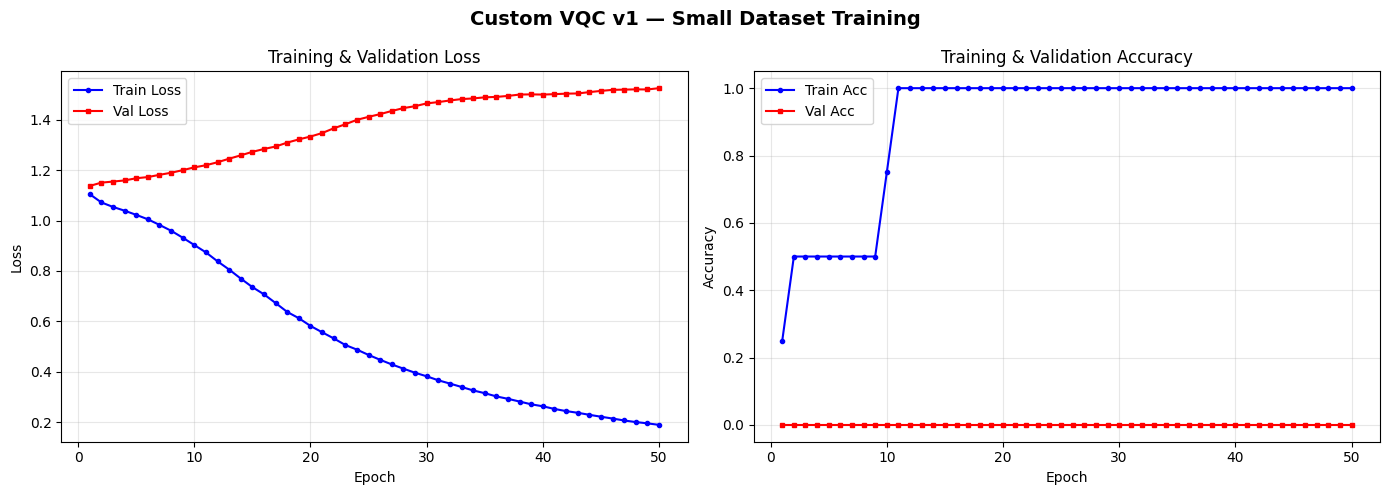

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = range(1, EPOCHS + 1)

# ── Loss Curve ──
ax1.plot(epochs_range, history["train_loss"], "b-o", markersize=3, label="Train Loss")
ax1.plot(epochs_range, history["val_loss"],   "r-s", markersize=3, label="Val Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.set_title("Training & Validation Loss")
ax1.legend()
ax1.grid(True, alpha=0.3)

# ── Accuracy Curve ──
ax2.plot(epochs_range, history["train_acc"], "b-o", markersize=3, label="Train Acc")
ax2.plot(epochs_range, history["val_acc"],   "r-s", markersize=3, label="Val Acc")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.set_title("Training & Validation Accuracy")
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.set_ylim(-0.05, 1.05)

plt.suptitle("Custom VQC v1 — Small Dataset Training", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

---
## Step 10 — Evaluate on the Full Dataset

Since the dataset is tiny, we also evaluate on **all 6 sentences** to see overall model behaviour.

In [12]:
# ─── Predict on ALL data ───
model.eval()
with torch.no_grad():
    all_x = torch.tensor(X, dtype=torch.float32).to(device)
    logits = model(all_x)
    probs  = torch.softmax(logits, dim=-1)
    preds  = logits.argmax(dim=-1).cpu().numpy()

# ─── Print predictions ───
print(f"{'Sentence':<55} {'True':>8} {'Pred':>8} {'Correct':>8}")
print("─" * 85)
for i, sent in enumerate(sentences):
    true_label = label_names[labels[i]]
    pred_label = label_names[preds[i]]
    correct = "✅" if labels[i] == preds[i] else "❌"
    print(f"{sent[:53]:<55} {true_label:>8} {pred_label:>8} {correct:>8}")

# ─── Classification Report ───
print(f"\n{'='*50}")
print("  Classification Report (all 6 sentences)")
print(f"{'='*50}")
print(classification_report(y, preds, target_names=label_names, zero_division=0))

overall_acc = accuracy_score(y, preds)
print(f"Overall Accuracy: {overall_acc:.2%}")

Sentence                                                    True     Pred  Correct
─────────────────────────────────────────────────────────────────────────────────────
I am so happy today, everything is wonderful!                joy      joy        ✅
This is the best day of my life, I feel great!               joy      joy        ✅
I feel very sad and lonely right now.                    sadness  sadness        ✅
Everything makes me cry, I miss my friends.              sadness      joy        ❌
I am furious about what happened, it's unfair!             anger    anger        ✅
This makes me so angry, I can't stand it!                  anger      joy        ❌

  Classification Report (all 6 sentences)
              precision    recall  f1-score   support

         joy       0.50      1.00      0.67         2
     sadness       1.00      0.50      0.67         2
       anger       1.00      0.50      0.67         2

    accuracy                           0.67         6
   macro avg      

---
## Step 11 — Inspect Quantum Circuit

Let's visualise what the quantum circuit looks like using PennyLane's drawer.

/tmp/ipykernel_2055/1147933946.py:9: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


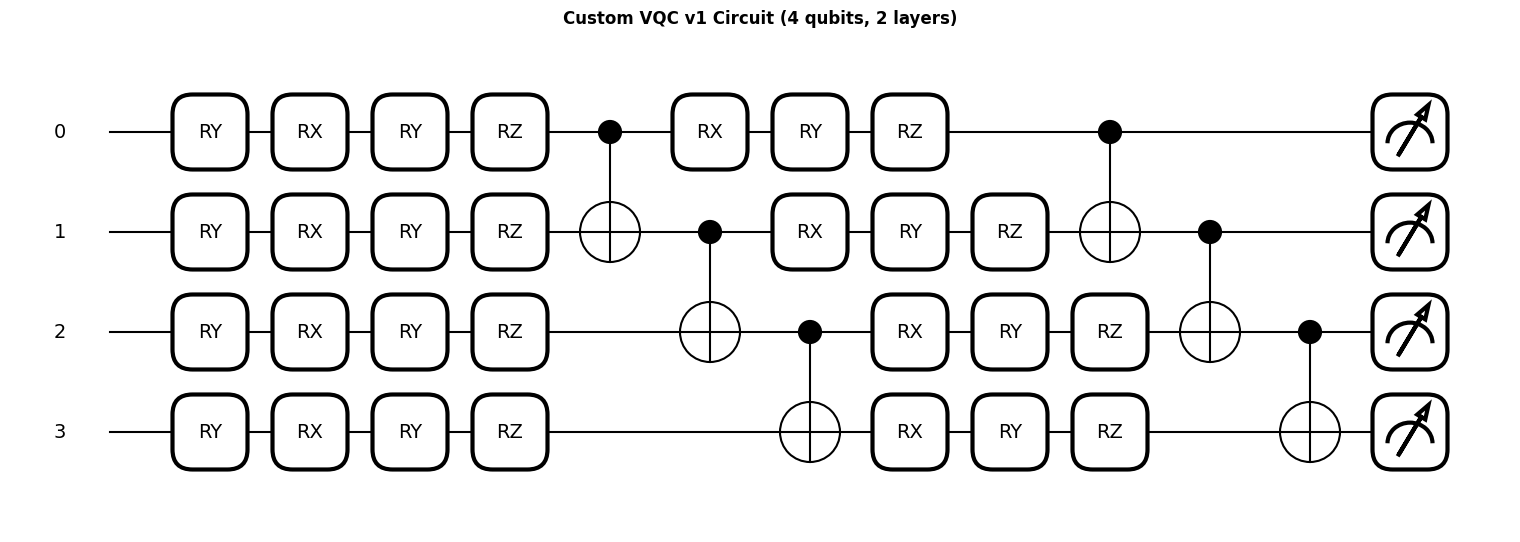

In [13]:
# Draw the circuit with a dummy input
dummy_input = torch.randn(N_QUBITS)
dummy_weights = torch.randn(N_LAYERS, N_QUBITS, 3)

circuit, _ = create_custom_vqc_v1(N_QUBITS, N_LAYERS)

fig, ax = qml.draw_mpl(circuit)(dummy_input, dummy_weights)
plt.title("Custom VQC v1 Circuit (4 qubits, 2 layers)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

---
## Step 12 — Try Your Own Sentences!

Test the trained model on new sentences. Remember: the TF-IDF vocabulary is tiny (fit on only 6 sentences), so out-of-vocabulary words will be ignored.

In [14]:
# ─── Test with new sentences ───
test_sentences = [
    "I feel so happy and excited!",
    "This is making me really sad.",
    "I am extremely angry about this!",
]

# Embed using the SAME fitted vectorizer
X_test = vectorizer.transform(test_sentences).toarray()

model.eval()
with torch.no_grad():
    test_x = torch.tensor(X_test, dtype=torch.float32).to(device)
    test_logits = model(test_x)
    test_probs  = torch.softmax(test_logits, dim=-1)
    test_preds  = test_logits.argmax(dim=-1).cpu().numpy()

print("\n🔮 Predictions on new sentences:\n")
for i, sent in enumerate(test_sentences):
    pred_label = label_names[test_preds[i]]
    prob_str = " | ".join(
        f"{label_names[j]}: {test_probs[i][j]:.2%}" for j in range(num_classes)
    )
    print(f"  \"{sent}\"")
    print(f"  → Predicted: {pred_label}  ({prob_str})")
    print()


🔮 Predictions on new sentences:

  "I feel so happy and excited!"
  → Predicted: joy  (joy: 62.29% | sadness: 12.58% | anger: 25.12%)

  "This is making me really sad."
  → Predicted: joy  (joy: 67.11% | sadness: 8.81% | anger: 24.09%)

  "I am extremely angry about this!"
  → Predicted: joy  (joy: 59.53% | sadness: 3.44% | anger: 37.03%)



---
## 💡 Notes & Next Steps

### What we demonstrated
- The full **TF-IDF → FeatureCompressor → VQC → Linear** pipeline from your project
- Training converges on a 6-sentence dataset — the VQC can memorise it

### Important caveats
- **6 sentences is far too few for generalisation** — this is a proof-of-concept only
- TF-IDF vocabulary from 6 sentences is extremely limited
- Validation metrics are unreliable with only 2 samples

### To scale up
1. **More data**: Use 50–200+ sentences per class for meaningful results
2. **Better embeddings**: Switch from TF-IDF to BERT/mBERT (your project supports this)
3. **Upload your project**: Zip and upload the full `JU/` project to Colab, then use the actual `CustomVQCClassifier` from `hybrid_model.py`
4. **Try other VQC versions**: `v2` (data re-uploading) and `v3` (ring entanglement)

### How to use your full project in Colab
```python
# Upload JU_project.zip to Colab, then:
!unzip JU_project.zip
!pip install -r requirements.txt
import sys; sys.path.insert(0, '.')
from models.custom_vqc.hybrid_model import CustomVQCClassifier
```